# Снижение активности по картам: кто, насколько и за счёт чего

**Автор:** <br>
**Период данных:** 2024-01-01 — 2025-06-30 <br>
**Подготовлено для:** департамент розничных продуктов, банк «Меридиан»

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10})
pd.set_option("display.max_colwidth", None)

clean = pd.read_parquet("clean_data.parquet").set_index("client_id")
monthly = pd.read_parquet("monthly_ops.parquet")
log = pd.read_csv("cleaning_log.csv")
campaign = pd.read_csv("campaign_list.csv")
facts = json.load(open("facts.json", encoding="utf-8"))
R = Path("report_data")
channel_m = pd.read_csv(R / "channel_monthly.csv")
g_cat = pd.read_csv(R / "group_change_category.csv")
g_ch = pd.read_csv(R / "group_change_channel.csv")
profile = pd.read_csv(R / "group_profile.csv").set_index("group")
excl = pd.read_csv(R / "exclusions.csv").set_index("шаг")
txn_funnel = pd.read_csv(R / "txn_funnel.csv").set_index("шаг")
hyp = pd.read_csv(R / "hypotheses.csv").set_index("гипотеза")
thr = pd.read_csv(R / "thresholds.csv", index_col=0)["threshold"]

def M(text):
    display(Markdown(text))

def n(x):
    """Целое с неразрывным пробелом между тысячами: 5 667."""
    return f"{int(round(x)):,}".replace(",", " ")

def p(x, d=1, sign=True):
    """Доля (0.2 → «+20,0 %»), десятичная запятая."""
    s = f"{x * 100:+.{d}f}" if sign else f"{x * 100:.{d}f}"
    return s.replace(".", ",").replace("-", "−") + " %"

SHORT = {g: g.split(":")[0] for g in clean["group"].dropna().unique()}       # «G1 Массовый без приложения»
GID = {g: g.split()[0] for g in SHORT}                                          # «G1»

meas = clean[clean["measurable"]]
mass = meas["segment"] == "Массовый"
med = lambda s: s.median()

# помесячные итоги по всем клиентам в расчёте активности
monthly["month"] = pd.PeriodIndex(monthly["month"], freq="M")
by_month = monthly.groupby("month")["ops"].sum()
active = monthly[monthly["ops"] > 0].groupby("month")["client_id"].nunique()
y24 = by_month[by_month.index.year == 2024]
y25 = by_month[by_month.index.year == 2025]
h1_24 = y24[y24.index.month <= 6]
chg_year = y25.mean() / y24.mean() - 1
chg_h1 = y25.mean() / h1_24.mean() - 1

ch = channel_m.pivot(index="month", columns="channel", values="ops")
ch.index = pd.PeriodIndex(ch.index, freq="M")
ch_idx = ch / ch[ch.index.year == 2024].mean()
ch_25 = ch[ch.index.year == 2025].mean() / ch[ch.index.year == 2024].mean() - 1

G = clean[clean["group"].notna()]
sizes = G["group"].value_counts().sort_index()

## 1. Главное

In [2]:
noapp, withapp = meas.loc[mass & ~meas["has_mobile_app"], "change_A"], meas.loc[mass & meas["has_mobile_app"], "change_A"]
M(f"""
1. **Активность снизилась: у половины клиентов число операций в месяц упало не меньше чем на {p(-med(meas['change_A']), sign=False)}** (медиана, I пол. 2025 к 2024, n = {n(len(meas))} клиентов). Если сравнивать с теми же месяцами 2024 и убрать сезонность, медиана {p(med(meas['change_B']))}. Клиенты платят реже, но не исчезают: активных клиентов в месяц почти столько же ({n(active[active.index.year == 2025].min())}–{n(active[active.index.year == 2025].max())} в 2025).
2. **Падение сосредоточено в «Массовом» сегменте и прежде всего у клиентов без мобильного приложения:** медиана {p(med(meas.loc[mass, 'change_A']))} в «Массовом» против {p(med(meas.loc[~mass, 'change_A']))} в остальных; внутри «Массового» без приложения {p(med(noapp))}, с приложением {p(med(withapp))}.
3. **Оплата телефоном растёт ({p(ch_25['Токен'])} операций «Токеном» в месяц, I пол. 2025 к 2024, все клиенты в расчёте), но у клиентов с сильным падением падают все каналы сразу** — это уход от карты, а не смена способа оплаты.
4. **В кампанию предлагаем {n(len(G))} клиентов в {len(sizes)} группах:** {'; '.join(f'{SHORT[g]} — {n(v)}' for g, v in sizes.items())}.
""")


1. **Активность снизилась: у половины клиентов число операций в месяц упало не меньше чем на 20,9 %** (медиана, I пол. 2025 к 2024, n = 5 099 клиентов). Если сравнивать с теми же месяцами 2024 и убрать сезонность, медиана −14,5 %. Клиенты платят реже, но не исчезают: активных клиентов в месяц почти столько же (4 801–5 135 в 2025).
2. **Падение сосредоточено в «Массовом» сегменте и прежде всего у клиентов без мобильного приложения:** медиана −36,7 % в «Массовом» против −11,0 % в остальных; внутри «Массового» без приложения −54,3 %, с приложением −26,0 %.
3. **Оплата телефоном растёт (+29,9 % операций «Токеном» в месяц, I пол. 2025 к 2024, все клиенты в расчёте), но у клиентов с сильным падением падают все каналы сразу** — это уход от карты, а не смена способа оплаты.
4. **В кампанию предлагаем 1 896 клиентов в 4 группах:** G1 Массовый без приложения — 617; G2 Массовый с приложением — 642; G3 Немассовые любители кафе — 344; G4 Немассовые — 293.


## 2. Контекст

Клиенты банка стали реже пользоваться картами. Департамент готовит кампанию по возврату активности и просит определить, к кому идти и о чём говорить: от 3 до 5 групп по 150 человек и больше, всего не более 2 000 клиентов. Каждая группа описана правилом «кто это» + «что с ними произошло», и каждый клиент попадает ровно в одну группу.

## 3. Данные и ограничения

In [3]:
M(f"""
**Данные.** Справочник действующих клиентов на 30.06.2025 ({n(facts['clients_raw'])} строк, после удаления дублей — {n(facts['clients_clean'])} клиентов) и операции за 2024-01 … 2025-06 ({n(facts['txn_raw'])} строк, после удаления дублей — {n(facts['txn_clean'])}). В расчёт активности идут только успешные операции в рублях за период, у клиентов из справочника: **{n(facts['txn_act_rows'])} операций {n(facts['txn_act_clients'])} клиентов**.

**Что исключено:** {n(txn_funnel.loc['статус «успешно»', 'отсеяно операций'])} неуспешных операций (отклонённые и возвраты), {n(txn_funnel.loc['операция в рублях', 'отсеяно операций'])} операций в EUR/USD (курсов нет; {p(txn_funnel.loc['операция в рублях', 'отсеяно операций'] / txn_funnel.loc['статус «успешно»', 'операций'], 1, sign=False)} из {n(txn_funnel.loc['статус «успешно»', 'операций'])} успешных операций периода), {n(txn_funnel.loc['клиент есть в справочнике', 'отсеяно операций'])} операций {n(facts['lost_clients'])} клиентов, которых нет в справочнике действующих.

**Метрика активности — число успешных операций в месяц по всем каналам** (Карта, Токен, СБП, Онлайн-банк). Изменение у клиента = среднее в месяц за янв–июн 2025 / среднее в месяц за 2024 − 1; база считается только по месяцам, когда текущая карта уже открыта, и нужна длиной не меньше {int(thr['MIN_BASE_MONTHS'])} месяцев — так метрика считается для {n(facts['metric_clients'])} клиентов. Число операций, а не сумма: задача — вернуть привычку пользоваться картой, а суммы сильно зависят от единичных крупных покупок. **Метрика не увидит:** клиентов, которых уже нет в справочнике; клиентов с картой, открытой после сентября 2024; снижение сумм при той же частоте; перенос оплат в другой банк. База «весь 2024» включает декабрьский пик, поэтому падение завышено примерно на {(med(meas['change_B']) - med(meas['change_A'])) * 100:.0f} п.п. — проверено расчётом от I пол. 2024.

**Чего в данных нет:** зачислений зарплаты (источник зарплаты — со слов клиента), операций по картам других банков, причин отказа от карты, истории коммуникаций. Доход не указан у {n(clean['monthly_income'].isna().sum())} из {n(len(clean))} клиентов ({p(clean['monthly_income'].isna().mean(), 0, sign=False)}), оценки сервиса нет у {n(clean['satisfaction_score'].isna().sum())} ({p(clean['satisfaction_score'].isna().mean(), 0, sign=False)}); у {n(facts['date_only_share'] * facts['txn_raw'])} из {n(facts['txn_raw'])} исходных операций ({p(facts['date_only_share'], 0, sign=False)}) есть только дата без времени.
""")


**Данные.** Справочник действующих клиентов на 30.06.2025 (5 722 строк, после удаления дублей — 5 667 клиентов) и операции за 2024-01 … 2025-06 (626 301 строк, после удаления дублей — 624 801). В расчёт активности идут только успешные операции в рублях за период, у клиентов из справочника: **576 422 операций 5 653 клиентов**.

**Что исключено:** 19 777 неуспешных операций (отклонённые и возвраты), 2 418 операций в EUR/USD (курсов нет; 0,4 % из 604 949 успешных операций периода), 26 109 операций 333 клиентов, которых нет в справочнике действующих.

**Метрика активности — число успешных операций в месяц по всем каналам** (Карта, Токен, СБП, Онлайн-банк). Изменение у клиента = среднее в месяц за янв–июн 2025 / среднее в месяц за 2024 − 1; база считается только по месяцам, когда текущая карта уже открыта, и нужна длиной не меньше 3 месяцев — так метрика считается для 5 099 клиентов. Число операций, а не сумма: задача — вернуть привычку пользоваться картой, а суммы сильно зависят от единичных крупных покупок. **Метрика не увидит:** клиентов, которых уже нет в справочнике; клиентов с картой, открытой после сентября 2024; снижение сумм при той же частоте; перенос оплат в другой банк. База «весь 2024» включает декабрьский пик, поэтому падение завышено примерно на 6 п.п. — проверено расчётом от I пол. 2024.

**Чего в данных нет:** зачислений зарплаты (источник зарплаты — со слов клиента), операций по картам других банков, причин отказа от карты, истории коммуникаций. Доход не указан у 693 из 5 667 клиентов (12 %), оценки сервиса нет у 3 381 (60 %); у 49 803 из 626 301 исходных операций (8 %) есть только дата без времени.


## 4. Находки

### 4.1. В каждом месяце I полугодия 2025 операций меньше, чем в том же месяце 2024: −9,8 % без учёта сезонности

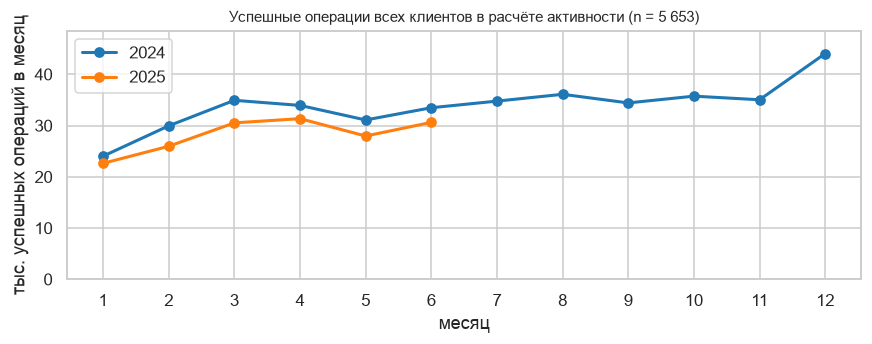

Форма линий одинаковая — январь низкий, к марту рост, — это сезонность. Но 2025 ниже 2024 в каждом месяце. К среднему за весь 2024 операций в месяц −17,0 %, к тем же месяцам 2024 — −9,8 %: разница — декабрьский пик в базе. Число активных клиентов в месяц почти не изменилось, падает частота операций.

In [4]:
M(f"### 4.1. В каждом месяце I полугодия 2025 операций меньше, чем в том же месяце 2024: {p(chg_h1)} без учёта сезонности")
fig, ax = plt.subplots(figsize=(8, 3.2))
for year, s, color in [(2024, y24, "tab:blue"), (2025, y25, "tab:orange")]:
    ax.plot(s.index.month, s.values / 1000, marker="o", lw=2, color=color, label=str(year))
ax.set(xticks=range(1, 13), xlabel="месяц", ylabel="тыс. успешных операций в месяц", ylim=(0, by_month.max() / 1000 * 1.1),
       title=f"Успешные операции всех клиентов в расчёте активности (n = {n(facts['txn_act_clients'])})")
ax.legend(); plt.tight_layout(); plt.show()
M(f"""Форма линий одинаковая — январь низкий, к марту рост, — это сезонность. Но 2025 ниже 2024 в каждом месяце. К среднему за весь 2024 операций в месяц {p(chg_year)}, к тем же месяцам 2024 — {p(chg_h1)}: разница — декабрьский пик в базе. Число активных клиентов в месяц почти не изменилось, падает частота операций.""")

### 4.2. Падение сосредоточено у «Массовых» клиентов, и сильнее всего — без мобильного приложения

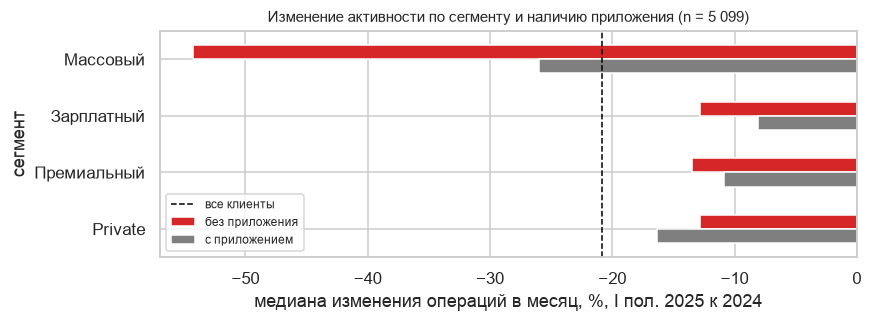

Внутри «Массового» без приложения медиана −54,3 % (n = 1 057), с приложением −26,0 % (n = 1 589); в остальных сегментах приложение почти ничего не меняет. Возраст действует через приложение: среди «Массовых» без приложения падение одинаковое у клиентов до 45 лет (−54,8 %, n = 171) и 70+ (−56,6 %, n = 249); приложение есть у 31 % «Массовых» 70+ против 79 % до 45 лет. Различия по городу, источнику зарплаты и доходу тоже объясняются долей «Массового» сегмента (раздел 7).

In [5]:
M("### 4.2. Падение сосредоточено у «Массовых» клиентов, и сильнее всего — без мобильного приложения")
t = (meas.assign(приложение=meas["has_mobile_app"].map({True: "с приложением", False: "без приложения"}))
         .groupby(["segment", "приложение"])["change_A"].median().mul(100).unstack())
t = t.loc[["Массовый", "Зарплатный", "Премиальный", "Private"]]
ax = t.plot.barh(figsize=(8, 3), color=["tab:red", "tab:grey"])
ax.axvline(med(meas["change_A"]) * 100, color="black", ls="--", lw=1, label="все клиенты")
ax.set(xlabel="медиана изменения операций в месяц, %, I пол. 2025 к 2024", ylabel="сегмент", title=f"Изменение активности по сегменту и наличию приложения (n = {n(len(meas))})")
ax.invert_yaxis(); ax.legend(fontsize=8, loc="lower left"); plt.tight_layout(); plt.show()
old = meas["age"] >= 70
young = meas["age"] < 45
na = mass & ~meas["has_mobile_app"]
wa = mass & meas["has_mobile_app"]
M(f"""Внутри «Массового» без приложения медиана {p(med(meas.loc[na, 'change_A']))} (n = {n(na.sum())}), с приложением {p(med(meas.loc[wa, 'change_A']))} (n = {n(wa.sum())}); в остальных сегментах приложение почти ничего не меняет. Возраст действует через приложение: среди «Массовых» без приложения падение одинаковое у клиентов до 45 лет ({p(med(meas.loc[na & young, 'change_A']))}, n = {n((na & young).sum())}) и 70+ ({p(med(meas.loc[na & old, 'change_A']))}, n = {n((na & old).sum())}); приложение есть у {p(meas.loc[mass & old, 'has_mobile_app'].mean(), 0, sign=False)} «Массовых» 70+ против {p(meas.loc[mass & young, 'has_mobile_app'].mean(), 0, sign=False)} до 45 лет. Различия по городу, источнику зарплаты и доходу тоже объясняются долей «Массового» сегмента (раздел 7).""")

### 4.3. У части клиентов активность почти ушла — распределение изменений двугорбое

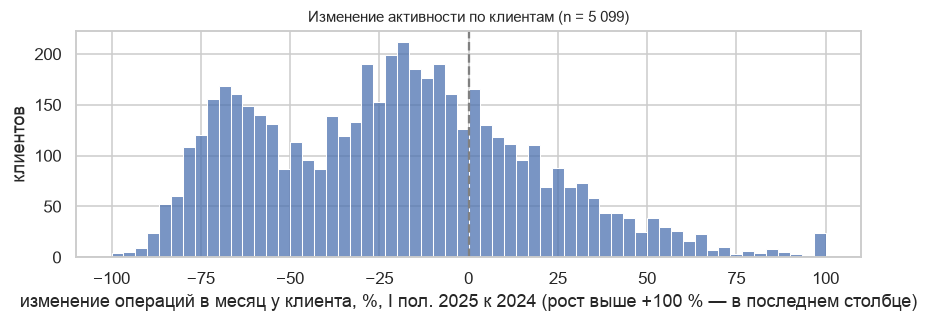

Один «горб» — около −15 %: общее снижение. Второй — около −70 %: у 1 412 клиентов (28 % из 5 099) операций стало вдвое меньше и ниже. Среди «Массовых» таких 1 107 из 2 646 (42 %), среди остальных — 305 из 2 453 (12 %). Группы кампании строятся вокруг второго «горба».

In [6]:
M("### 4.3. У части клиентов активность почти ушла — распределение изменений двугорбое")
fig, ax = plt.subplots(figsize=(8, 3))
sns.histplot(meas["change_A"].clip(upper=1) * 100, bins=60, ax=ax)
ax.axvline(0, color="grey", ls="--")
ax.set(xlabel="изменение операций в месяц у клиента, %, I пол. 2025 к 2024 (рост выше +100 % — в последнем столбце)", ylabel="клиентов",
       title=f"Изменение активности по клиентам (n = {n(len(meas))})")
plt.tight_layout(); plt.show()
deep = meas["change_A"] <= -0.5
M(f"""Один «горб» — около −15 %: общее снижение. Второй — около −70 %: у {n(deep.sum())} клиентов ({p(deep.mean(), 0, sign=False)} из {n(len(meas))}) операций стало вдвое меньше и ниже. Среди «Массовых» таких {n(deep[mass].sum())} из {n(mass.sum())} ({p(deep[mass].mean(), 0, sign=False)}), среди остальных — {n(deep[~mass].sum())} из {n((~mass).sum())} ({p(deep[~mass].mean(), 0, sign=False)}). Группы кампании строятся вокруг второго «горба».""")

### 4.4. Оплаты телефоном выросли на 30 %, оплаты картой упали на 27 %

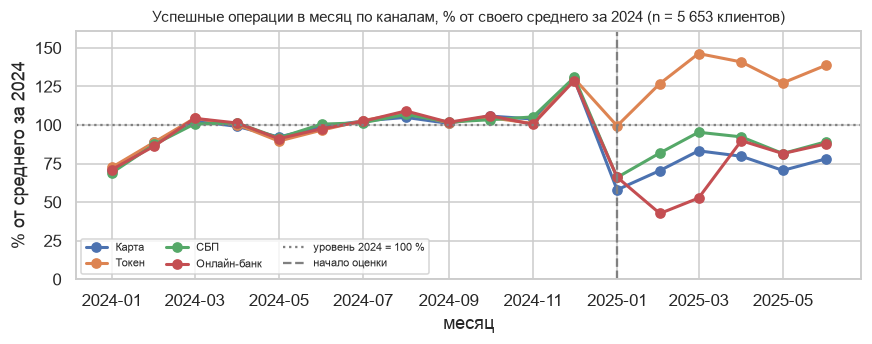

Весь 2024 каналы двигались вместе. В 2025 «Токен» (оплата телефоном) выше уровня 2024, «Карта» — ниже: часть клиентов перешла на телефон, поэтому метрика считается по всем каналам. «Онлайн-банк» в феврале–марте 2025 упал до 43 % и 53 % уровня 2024 и в апреле вернулся к 90 %; причину по данным установить нельзя. У клиентов из групп кампании «Токен» падает вместе с остальными каналами (раздел 5).

In [7]:
M(f"### 4.4. Оплаты телефоном выросли на {p(ch_25['Токен'], 0, sign=False)}, оплаты картой упали на {p(-ch_25['Карта'], 0, sign=False)}")
fig, ax = plt.subplots(figsize=(8, 3.2))
for c in ["Карта", "Токен", "СБП", "Онлайн-банк"]:
    ax.plot(ch_idx.index.to_timestamp(), ch_idx[c] * 100, marker="o", lw=2, label=c)
ax.axhline(100, color="grey", ls=":", label="уровень 2024 = 100 %")
ax.axvline(pd.Timestamp("2025-01-01"), color="grey", ls="--", label="начало оценки")
ax.set(xlabel="месяц", ylabel="% от среднего за 2024", title=f"Успешные операции в месяц по каналам, % от своего среднего за 2024 (n = {n(facts['txn_act_clients'])} клиентов)", ylim=(0, ch_idx.max().max() * 110))
ax.legend(fontsize=7, ncol=3, loc="lower left"); plt.tight_layout(); plt.show()
ob = ch_idx["Онлайн-банк"]
M(f"""Весь 2024 каналы двигались вместе. В 2025 «Токен» (оплата телефоном) выше уровня 2024, «Карта» — ниже: часть клиентов перешла на телефон, поэтому метрика считается по всем каналам. «Онлайн-банк» в феврале–марте 2025 упал до {p(ob['2025-02'], 0, sign=False)} и {p(ob['2025-03'], 0, sign=False)} уровня 2024 и в апреле вернулся к {p(ob['2025-04'], 0, sign=False)}; причину по данным установить нельзя. У клиентов из групп кампании «Токен» падает вместе с остальными каналами (раздел 5).""")

## 5. Группы для кампании

,кто,что произошло,клиентов,медиана изменения,март–июнь к 2024
G1,«Массовый» сегмент без мобильного приложения,с января 2025 активность упала (не меньше чем на 30 %) и не восстановилась,617,−65 %,32 %
G2,«Массовый» сегмент с мобильным приложением,с января 2025 активность упала (не меньше чем на 30 %) и не восстановилась,642,−60 %,40 %
G3,остальные сегменты; кафе и рестораны — не меньше 20 % операций в 2024,"операций в кафе стало вдвое меньше и ниже (−50 % и ниже), остальные траты почти не изменились",344,−31 %,71 %
G4,"остальные сегменты («Зарплатный», «Премиальный», Private)",активность упала не меньше чем на 30 % и к весне не вернулась (март–июнь < 70 % уровня 2024),293,−60 %,42 %


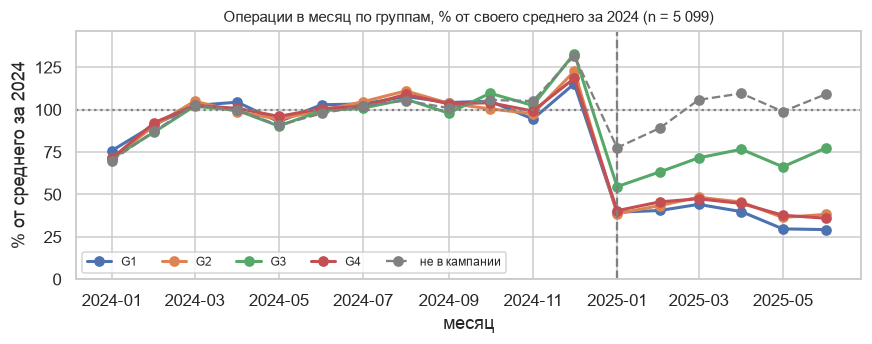

In [8]:
WHO = {"G1": "«Массовый» сегмент без мобильного приложения",
       "G2": "«Массовый» сегмент с мобильным приложением",
       "G3": f"остальные сегменты; кафе и рестораны — не меньше {p(thr['CAFE_SHARE'], 0, sign=False)} операций в 2024",
       "G4": "остальные сегменты («Зарплатный», «Премиальный», Private)"}
WHAT = {"G1": f"с января 2025 активность упала (не меньше чем на {p(-thr['DROP'], 0, sign=False)}) и не восстановилась",
        "G2": f"с января 2025 активность упала (не меньше чем на {p(-thr['DROP'], 0, sign=False)}) и не восстановилась",
        "G3": f"операций в кафе стало вдвое меньше и ниже ({p(thr['CAFE_DROP'], 0)} и ниже), остальные траты почти не изменились",
        "G4": f"активность упала не меньше чем на {p(-thr['DROP'], 0, sign=False)} и к весне не вернулась (март–июнь < {p(thr['NOT_BACK'], 0, sign=False)} уровня 2024)"}
tab = pd.DataFrame({
    "кто": [WHO[GID[g]] for g in sizes.index],
    "что произошло": [WHAT[GID[g]] for g in sizes.index],
    "клиентов": sizes.values,
    "медиана изменения": [p(med(G.loc[G['group'] == g, 'change_A']), 0) for g in sizes.index],
    "март–июнь к 2024": [p(med(G.loc[G['group'] == g, 'spring_ratio']), 0, sign=False) for g in sizes.index],
}, index=[GID[g] for g in sizes.index])
display(tab)

# динамика групп: операций в месяц, % от среднего за 2024
grp = clean["group"].map(GID).fillna("не в кампании")
mm = monthly[monthly["client_id"].isin(meas.index)].assign(g=lambda d: d["client_id"].map(grp))
gi = mm.groupby(["g", "month"])["ops"].sum().unstack()
gi = gi.div(gi.loc[:, gi.columns.year == 2024].mean(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(8, 3.2))
for g, row in gi.iterrows():
    ax.plot(row.index.to_timestamp(), row.values, marker="o", lw=1.5 if g == "не в кампании" else 2,
            ls="--" if g == "не в кампании" else "-", color="grey" if g == "не в кампании" else None, label=g)
ax.axhline(100, color="grey", ls=":"); ax.axvline(pd.Timestamp("2025-01-01"), color="grey", ls="--")
ax.set(xlabel="месяц", ylabel="% от среднего за 2024", ylim=(0, gi.max().max() * 1.1),
       title=f"Операции в месяц по группам, % от своего среднего за 2024 (n = {n(len(meas))})")
ax.legend(fontsize=8, ncol=5, loc="lower left"); plt.tight_layout(); plt.show()

In [9]:
cat = g_cat.assign(g=g_cat["grp"].map(lambda s: s.split()[0])).pivot(index="g", columns="category", values="change_pct")
chn = g_ch.assign(g=g_ch["grp"].map(lambda s: s.split()[0])).pivot(index="g", columns="channel", values="change_pct")
prof = profile.rename(index=lambda s: s.split()[0])
pc0 = lambda v: f"{v:+.0f}".replace("-", "−") + "\u00a0%"          # уже в процентах: −62 %
rng = lambda g, t=None: f"{pc0((t if t is not None else cat).loc[g].min())[:-2]}…{pc0((t if t is not None else cat).loc[g].max())}"
other_cafe = cat.drop(columns="Кафе и рестораны")
M(f"""
**Правило конфликтов:** клиент идёт в первую подходящую группу G1 → G4. G1/G2 и G3/G4 не пересекаются по сегменту; клиентов, подходящих и под G3, и под G4, относим к G3 — у неё причина конкретнее. Рассматриваются только клиенты с посчитанной метрикой, согласием на маркетинг и надёжной строкой в справочнике.

- **G1 — «Массовые» без приложения ({n(sizes.iloc[0])}).** С января активность упала примерно втрое и не вернулась. Падение одинаковое во всех категориях ({rng('G1')}) и каналах — клиент отходит от карты целиком, а не от отдельного вида трат. Медиана возраста {prof.loc['G1', 'возраст_медиана']:.0f} лет; приложения нет, поэтому связаться можно только звонком, СМС или в отделении.
- **G2 — «Массовые» с приложением ({n(sizes.iloc[1])}).** Та же картина, что у G1 ({rng('G2')} по категориям), и оплата телефоном тоже упала ({pc0(chn.loc['G2', 'Токен'])}) — приложение есть, но не удержало. Медиана возраста {prof.loc['G2', 'возраст_медиана']:.0f}; канал связи — приложение.
- **G3 — любители кафе вне «Массового» сегмента ({n(sizes.iloc[2])}).** Операций в кафе и ресторанах {pc0(cat.loc['G3', 'Кафе и рестораны'])}, по остальным категориям {rng('G3', other_cafe)} — почти как у клиентов вне кампании. Клиент остался, но перестал платить картой в одной категории.
- **G4 — остальные сегменты, не вернувшиеся после января ({n(sizes.iloc[3])}).** У большинства клиентов этих сегментов январский провал к марту исчез, у этих в марте–июне {p(prof.loc['G4', 'март_июнь_к_базе'], 0, sign=False)} уровня 2024 во всех категориях ({rng('G4')}).

Почему клиенты так себя повели (например, перевели траты в другой банк), в данных не видно: в них только операции по нашим картам.
""")


**Правило конфликтов:** клиент идёт в первую подходящую группу G1 → G4. G1/G2 и G3/G4 не пересекаются по сегменту; клиентов, подходящих и под G3, и под G4, относим к G3 — у неё причина конкретнее. Рассматриваются только клиенты с посчитанной метрикой, согласием на маркетинг и надёжной строкой в справочнике.

- **G1 — «Массовые» без приложения (617).** С января активность упала примерно втрое и не вернулась. Падение одинаковое во всех категориях (−68…−59 %) и каналах — клиент отходит от карты целиком, а не от отдельного вида трат. Медиана возраста 59 лет; приложения нет, поэтому связаться можно только звонком, СМС или в отделении.
- **G2 — «Массовые» с приложением (642).** Та же картина, что у G1 (−67…−54 % по категориям), и оплата телефоном тоже упала (−51 %) — приложение есть, но не удержало. Медиана возраста 49; канал связи — приложение.
- **G3 — любители кафе вне «Массового» сегмента (344).** Операций в кафе и ресторанах −85 %, по остальным категориям −17…−9 % — почти как у клиентов вне кампании. Клиент остался, но перестал платить картой в одной категории.
- **G4 — остальные сегменты, не вернувшиеся после января (293).** У большинства клиентов этих сегментов январский провал к марту исчез, у этих в марте–июне 42 % уровня 2024 во всех категориях (−62…−54 %).

Почему клиенты так себя повели (например, перевели траты в другой банк), в данных не видно: в них только операции по нашим картам.


In [10]:
M("### Как на группы воздействовать")
app_n = G.groupby(G["group"].map(GID))["has_mobile_app"].agg(["sum", "size"])
seg = G.groupby(G["group"].map(GID))["segment"].agg(lambda x: ", ".join(f"{k} {v}" for k, v in x.value_counts().items()))
LEVER = {
    "G1": ("вернуть к карте целиком и дать цифровой канал",
           "напоминание о карте + предложение установить приложение; бонус за первые операции после паузы"),
    "G2": ("приложение есть, но не удержало — нужен повод платить",
           "персональное предложение в приложении на повседневные траты (продукты, транспорт), напоминание об оплате телефоном"),
    "G3": ("ушли только из кафе — остальное держится",
           "кешбэк или акция в кафе и ресторанах; трогать остальные траты не нужно"),
    "G4": ("сегменты с более ценными клиентами, которые не вернулись после января",
           "личный контакт (звонок, для «Премиального» и Private — через менеджера), выяснить причину и предложить условия"),
}
def channel(g):
    with_app, total = app_n.loc[g, "sum"], app_n.loc[g, "size"]
    if with_app == total: return f"пуш в приложении (приложение у всех {n(total)})"
    if with_app == 0: return f"СМС, звонок, отделение (приложения нет ни у кого из {n(total)})"
    return f"пуш — {n(with_app)} с приложением, СМС/звонок — {n(total - with_app)} без"
display(pd.DataFrame({
    "смысл группы": [LEVER[g][0] for g in app_n.index],
    "канал связи (из данных)": [channel(g) for g in app_n.index],
    "сегменты": [seg[g] for g in app_n.index],
    "что предложить (гипотеза кампании)": [LEVER[g][1] for g in app_n.index],
}, index=app_n.index.rename(None)))
M("Группы разделены так, чтобы у каждой был свой канал и свой повод для разговора: G1 и G2 падают одинаково, но до G1 можно дойти только без приложения. Канал связи взят из данных (наличие приложения; согласие на маркетинг есть у всех). Что предлагать — гипотеза для кампании, данными она не проверяется: её подтвердит только результат кампании.")

### Как на группы воздействовать

,смысл группы,канал связи (из данных),сегменты,что предложить (гипотеза кампании)
G1,вернуть к карте целиком и дать цифровой канал,"СМС, звонок, отделение (приложения нет ни у кого из 617)",Массовый 617,напоминание о карте + предложение установить приложение; бонус за первые операции после паузы
G2,"приложение есть, но не удержало — нужен повод платить",пуш в приложении (приложение у всех 642),Массовый 642,"персональное предложение в приложении на повседневные траты (продукты, транспорт), напоминание об оплате телефоном"
G3,ушли только из кафе — остальное держится,"пуш — 203 с приложением, СМС/звонок — 141 без","Премиальный 185, Зарплатный 112, Private 47",кешбэк или акция в кафе и ресторанах; трогать остальные траты не нужно
G4,"сегменты с более ценными клиентами, которые не вернулись после января","пуш — 141 с приложением, СМС/звонок — 152 без","Зарплатный 213, Премиальный 68, Private 12","личный контакт (звонок, для «Премиального» и Private — через менеджера), выяснить причину и предложить условия"


Группы разделены так, чтобы у каждой был свой канал и свой повод для разговора: G1 и G2 падают одинаково, но до G1 можно дойти только без приложения. Канал связи взят из данных (наличие приложения; согласие на маркетинг есть у всех). Что предлагать — гипотеза для кампании, данными она не проверяется: её подтвердит только результат кампании.

## 6. Кого не включаем и почему

In [11]:
left = meas[meas["group"].isna() & meas["marketing_opt_in"] & ~meas["conflict"] & (meas["change_A"] <= thr["DROP"])]
rows = [
    ("метрику не посчитать", excl.loc["метрика считается (база ≥ 3 мес.)", "не взяли"], "карта открыта после сентября 2024 — меньше трёх месяцев истории для сравнения"),
    ("нет согласия на маркетинг", excl.loc["есть согласие на маркетинг", "не взяли"], "по условию задачи коммуникация возможна только с согласия клиента"),
    ("две версии строки в справочнике", excl.loc["сегмент надёжен (нет двух версий строки)", "не взяли"], "сегмент или город неизвестен точно, а правила групп построены на сегменте"),
    ("активность не упала или вернулась", excl.loc["подходит под правило группы", "не взяли"], f"возвращать нечего; из них {n(len(left))} снизили активность на 30 % и больше, но к весне вернулись"),
    ("нет в справочнике действующих", facts["lost_clients"], "в справочнике на 30.06.2025 их нет — в кампанию берём только действующих клиентов"),
]
display(pd.DataFrame(rows, columns=["кто", "клиентов", "почему не берём"]).set_index("кто"))
M(f"Из {n(facts['clients_clean'])} клиентов справочника в кампанию входят {n(len(G))} — меньше лимита 2 000. Остаток не добираем: оставшиеся кандидаты либо не снизили активность, либо их нельзя взять.")

,клиентов,почему не берём
кто,,
метрику не посчитать,568,карта открыта после сентября 2024 — меньше трёх месяцев истории для сравнения
нет согласия на маркетинг,642,по условию задачи коммуникация возможна только с согласия клиента
две версии строки в справочнике,13,"сегмент или город неизвестен точно, а правила групп построены на сегменте"
активность не упала или вернулась,2548,"возвращать нечего; из них 59 снизили активность на 30 % и больше, но к весне вернулись"
нет в справочнике действующих,333,в справочнике на 30.06.2025 их нет — в кампанию берём только действующих клиентов


Из 5 667 клиентов справочника в кампанию входят 1 896 — меньше лимита 2 000. Остаток не добираем: оставшиеся кандидаты либо не снизили активность, либо их нельзя взять.

## 7. Что проверили и что не подтвердилось

In [12]:
keep = ["Новосибирск падает сильнее из-за города", "Зарплата в нашем банке удерживает активность",
        "Падение — это переход на оплату телефоном", "Всё падение — сезонность (декабрь в базе)", "Падают клиенты с низким доходом"]
h = hyp.loc[keep, ["проверка (медиана изменения метрики A)", "вывод"]].copy()
h.iloc[:, 0] = h.iloc[:, 0].str.replace(r"(\d)\.(\d)", r"\1,\2", regex=True).str.replace("-", "−")
display(h)

,проверка (медиана изменения метрики A),вывод
гипотеза,,
Новосибирск падает сильнее из-за города,"внутри «Массового»: Новосибирск −34,1 %, другие города −37,3 %; «Массовых» в Новосибирске 89% против 52% в среднем",не подтвердилась: разница — от доли «Массового» сегмента
Зарплата в нашем банке удерживает активность,"внутри «Массового»: «у нас» −39,8 %, «в другом банке» −35,1 %",не подтвердилась: общая разница — от состава сегментов
Падение — это переход на оплату телефоном,"у снизивших на ≥ 30 % операций «Токеном» в месяц стало больше только у 13%; «Токен» падает и в группах G1, G2, G4",не подтвердилась для снизивших; переход на телефон есть у остальных клиентов
Всё падение — сезонность (декабрь в базе),"к I пол. 2024: «Массовый» −33,3 %, остальные −3,0 %",не подтвердилась для «Массового»; у остальных сегментов — почти только сезонность
Падают клиенты с низким доходом,"внутри «Массового»: Q1 дохода −33,3 %, Q4 −38,5 %",не подтвердилась: разница по доходу в целом — от доли «Массового»


## 8. Приложение

### 8.1. Сводка журнала изменений

In [13]:
pick = {
    "полная копия строки клиента": "дубли клиентов",
    "у client_id две версии строки": "конфликтующие версии клиента",
    "полная копия операции": "дубли операций",
    "копия операции с датой без времени": "копии операций без времени",
    "один город записан по-разному": "написания городов",
    "одна категория записана по-разному": "написания категорий",
    "служебное значение -999": "служебное значение дохода",
    "доход меньше 1 000 ₽ — шкала неизвестна": "доход в неизвестной шкале",
    "отдельный блок нумерации ID ≥ 990000": "подозрительный блок операций",
}
s = log[log["issue"].isin(pick)].assign(тип=lambda d: d["issue"].map(pick))
display(s[["тип", "field", "n_rows", "action"]].rename(columns={"field": "поле", "n_rows": "строк", "action": "что сделано"}).set_index("тип"))
M(f"Полный журнал — `cleaning_log.csv` (решений: {len(log)}).")

,поле,строк,что сделано
тип,,,
дубли клиентов,все поля,40,удалено
конфликтующие версии клиента,"city, segment",15,"оставлена первая, флаг conflict"
дубли операций,все поля,1292,удалено
копии операций без времени,txn_datetime,208,удалена версия без времени
написания городов,city,1658,нормализация
написания категорий,category,53842,нормализация
служебное значение дохода,monthly_income,51,заменено на пропуск
доход в неизвестной шкале,monthly_income,139,заменено на пропуск
подозрительный блок операций,txn_id,220,"оставлено, флаг id_block"


Полный журнал — `cleaning_log.csv` (решений: 24).

### 8.2. Методика

In [15]:
M(f"""
- **Операции в расчёте:** после удаления дублей; дата 2024-01-01 … 2025-06-30; статус «успешно»; валюта RUB; клиент есть в справочнике.
- **Доступные месяцы клиента:** с первого полного месяца после открытия текущей карты.
- **ops_base** = операций за 2024 / доступных месяцев 2024; **ops_eval** = операций за янв–июн 2025 / 6; **change_A** = ops_eval / ops_base − 1. Метрика считается, если доступных месяцев в базе ≥ {int(thr['MIN_BASE_MONTHS'])}, в 2025 доступны все 6 и в базе есть операции.
- **Проверка B:** то же, база — янв–июн 2024 (медиана {p(med(meas['change_B']))}). **Проверка C:** сумма в рублях вместо числа операций (медиана {p(med(meas['change_C']))}).
- **spring_ratio** = (операций за март–июнь 2025 / 4) / ops_base. **cafe_share_base** — доля операций в «Кафе и рестораны» за 2024; **cafe_change** — изменение операций в кафе в месяц.
- **Пороги:** падение ≤ {p(thr['DROP'], 0)}; не вернулись — spring_ratio < {thr['NOT_BACK']:.2f}; любители кафе — доля ≥ {thr['CAFE_SHARE']:.2f} и cafe_change ≤ {p(thr['CAFE_DROP'], 0)}.
- **Отбор:** метрика посчитана, есть согласие на маркетинг, нет конфликтующих версий строки; группы G1 → G4, первое совпадение.
""")


- **Операции в расчёте:** после удаления дублей; дата 2024-01-01 … 2025-06-30; статус «успешно»; валюта RUB; клиент есть в справочнике.
- **Доступные месяцы клиента:** с первого полного месяца после открытия текущей карты.
- **ops_base** = операций за 2024 / доступных месяцев 2024; **ops_eval** = операций за янв–июн 2025 / 6; **change_A** = ops_eval / ops_base − 1. Метрика считается, если доступных месяцев в базе ≥ 3, в 2025 доступны все 6 и в базе есть операции.
- **Проверка B:** то же, база — янв–июн 2024 (медиана −14,5 %). **Проверка C:** сумма в рублях вместо числа операций (медиана −34,3 %).
- **spring_ratio** = (операций за март–июнь 2025 / 4) / ops_base. **cafe_share_base** — доля операций в «Кафе и рестораны» за 2024; **cafe_change** — изменение операций в кафе в месяц.
- **Пороги:** падение ≤ −30 %; не вернулись — spring_ratio < 0.70; любители кафе — доля ≥ 0.20 и cafe_change ≤ −50 %.
- **Отбор:** метрика посчитана, есть согласие на маркетинг, нет конфликтующих версий строки; группы G1 → G4, первое совпадение.


### 8.3. Использование ИИ

- ИИ-ассистент (Claude) помогал писать код аудита, очистки и графиков, предлагал гипотезы для проверки (Новосибирск, сезонность, доход, пол) и проверки качества (блок ID ≥ 990000, доход в тысячах).
- Сам проверял: кодировки и разделители файлов, дубли и конфликтующие строки, смысл каждого решения в журнале; отказался от предложения ИИ умножать доход < 1 000 на 1 000 — эти значения сброшены в пропуск.
- Формулировки о причинах (например, «клиент ушёл из банка») заменены на факты из данных.